# COU 07506 Digital Signal Processing — Week 04: z-Transform Laboratory, Poles, Zeros and Stability
Name: KILIAKI, LAURENT HASSANI 

Registration No.: 240647412039

Class: BEng24ETE-1 

Date: 26/11/2026

Pre-lab (Markdown cell)

(a) H(z) = 1/(1 − 0.9z⁻¹ + 0.81z⁻²). The poles are the roots of z² − 0.9z + 0.81 = 0:

z = [0.9 ± √(0.81 − 3.24)] / 2 = 0.45 ± j0.779, which is 0.9 e^(±jπ/3).

|p| = 0.9 < 1, so the causal system is stable.

(b) X(z) = 1/[(1 − 0.5z⁻¹)(1 − 0.25z⁻¹)] = A/(1 − 0.5z⁻¹) + B/(1 − 0.25z⁻¹), with

A = 1/(1 − 0.25/0.5) = 2
B = 1/(1 − 0.5/0.25) = −1

So X(z) = 2/(1 − 0.5z⁻¹) − 1/(1 − 0.25z⁻¹), giving x(n) = 2(0.5)ⁿ − (0.25)ⁿ. Check: x(0) = 1.

**Task 4.1: A pole-zero plotting function**

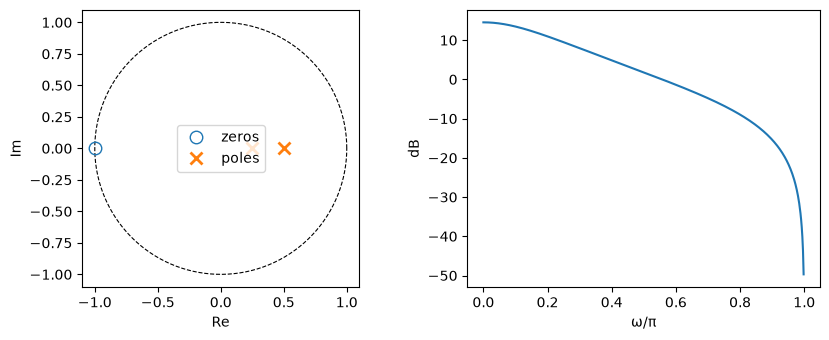

poles: [0.5  0.25] stable: True


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal


def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")

    return z, p


b, a = [1, 1], [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)
ax2.plot(w / np.pi, 20 * np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("dB")

plt.show()

print("poles:", p, "stable:", np.all(np.abs(p) < 1))

In [3]:
import numpy as np
from scipy import signal

a = [1, -0.75, 0.125]
n = np.arange(10)
impulse = np.zeros(10)
impulse[0] = 1

for b in ([1], [1, 1]):
    r, p, k = signal.residuez(b, a)
    h_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
    h_lf = signal.lfilter(b, a, impulse)

    print(f"b = {b}")
    print("residues:", r, "poles:", p)
    print("matches lfilter:", np.allclose(h_pf, h_lf))

b = [1]
residues: [-1.  2.] poles: [0.25 0.5 ]
matches lfilter: True
b = [1, 1]
residues: [-5.  6.] poles: [0.25 0.5 ]
matches lfilter: True


The stated expression \(6(0.5)^n-5(0.25)^n\) applies to \(b=[1]\). For \(b=[1,1]\), the numerator is \(1+z^{-1}\), so the residues differ; the code prints the corresponding partial-fraction result and checks it against lfilter.

**Task 4.2: Inverse z-transform with residuez**

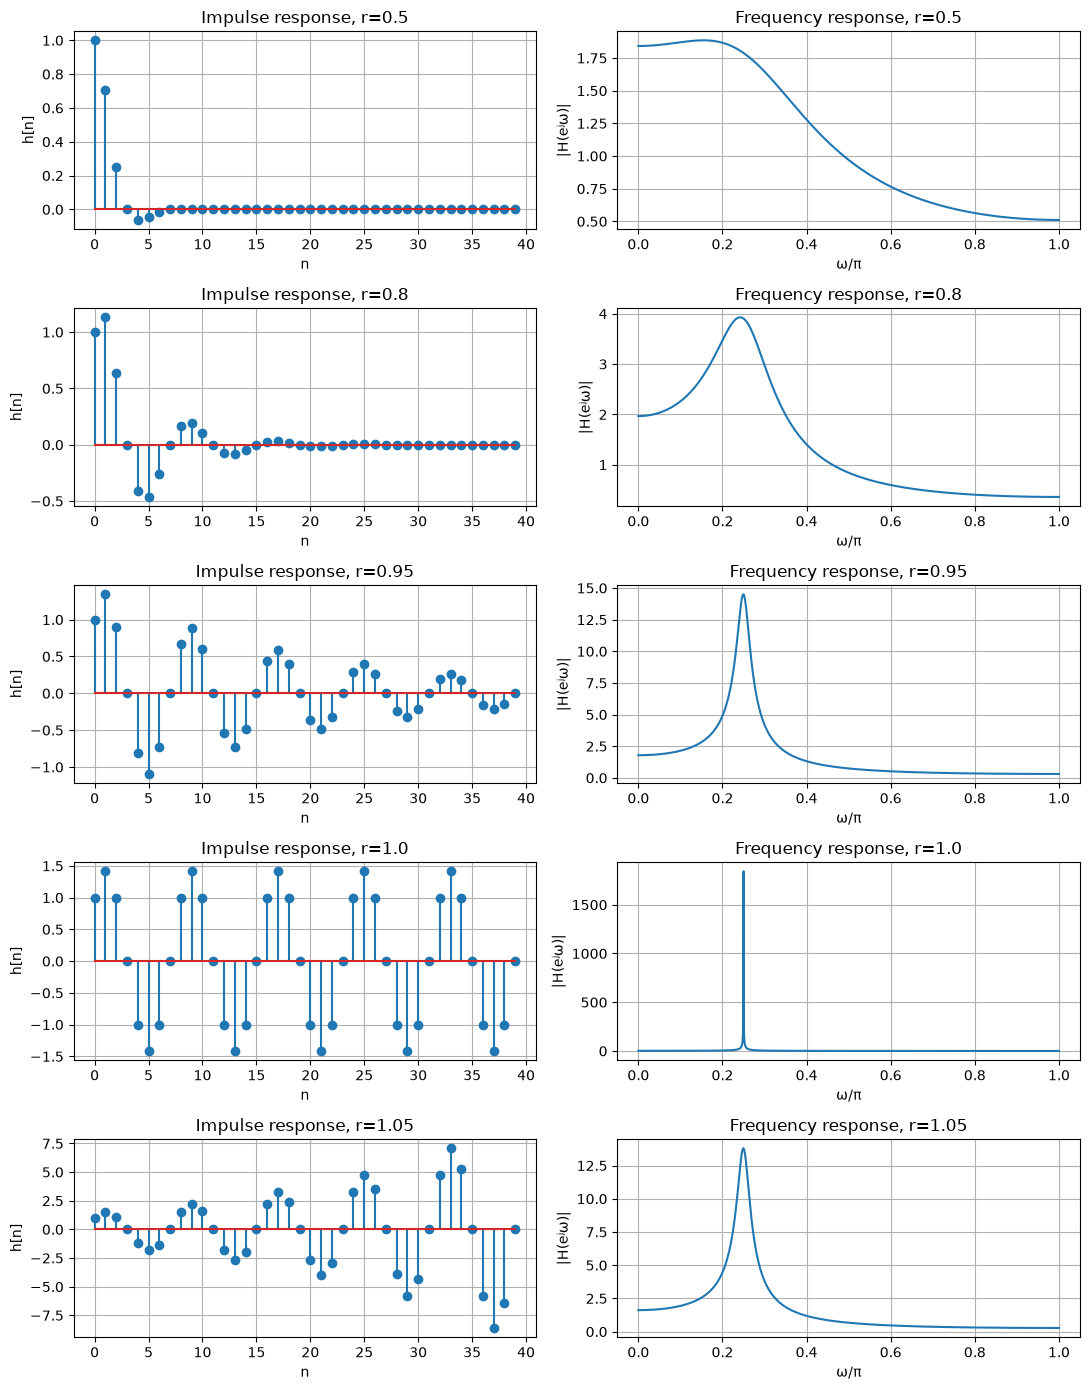

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
n = np.arange(40)
w = np.linspace(0, np.pi, 2048)

fig, axes = plt.subplots(len(r_values), 2, figsize=(11, 14))

for i, r in enumerate(r_values):
    a = [1, -2 * r * np.cos(np.pi / 4), r**2]

    impulse = np.zeros(40)
    impulse[0] = 1
    h = signal.lfilter([1], a, impulse)

    _, H = signal.freqz([1], a, worN=w)

    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(f"Impulse response, r={r}")
    axes[i, 0].set_xlabel("n")
    axes[i, 0].set_ylabel("h[n]")
    axes[i, 0].grid(True)

    axes[i, 1].plot(w / np.pi, np.abs(H))
    axes[i, 1].set_title(f"Frequency response, r={r}")
    axes[i, 1].set_xlabel("ω/π")
    axes[i, 1].set_ylabel("|H(eʲω)|")
    axes[i, 1].grid(True)

plt.tight_layout()
plt.show()

(a) H1: poles=[0.8+0.5j 0.8-0.5j], pole magnitudes=[0.94339811 0.94339811], stable, max |h[n]| over 100 samples=1.67
(b) H2: poles=[2.  0.5], pole magnitudes=[2.  0.5], unstable, max |h[n]| over 100 samples=1.27e+30
(c) H3: poles=[-1.   0.5], pole magnitudes=[1.  0.5], unstable, max |h[n]| over 100 samples=1
(d) H4: poles=[], pole magnitudes=[], stable, max |h[n]| over 100 samples=1


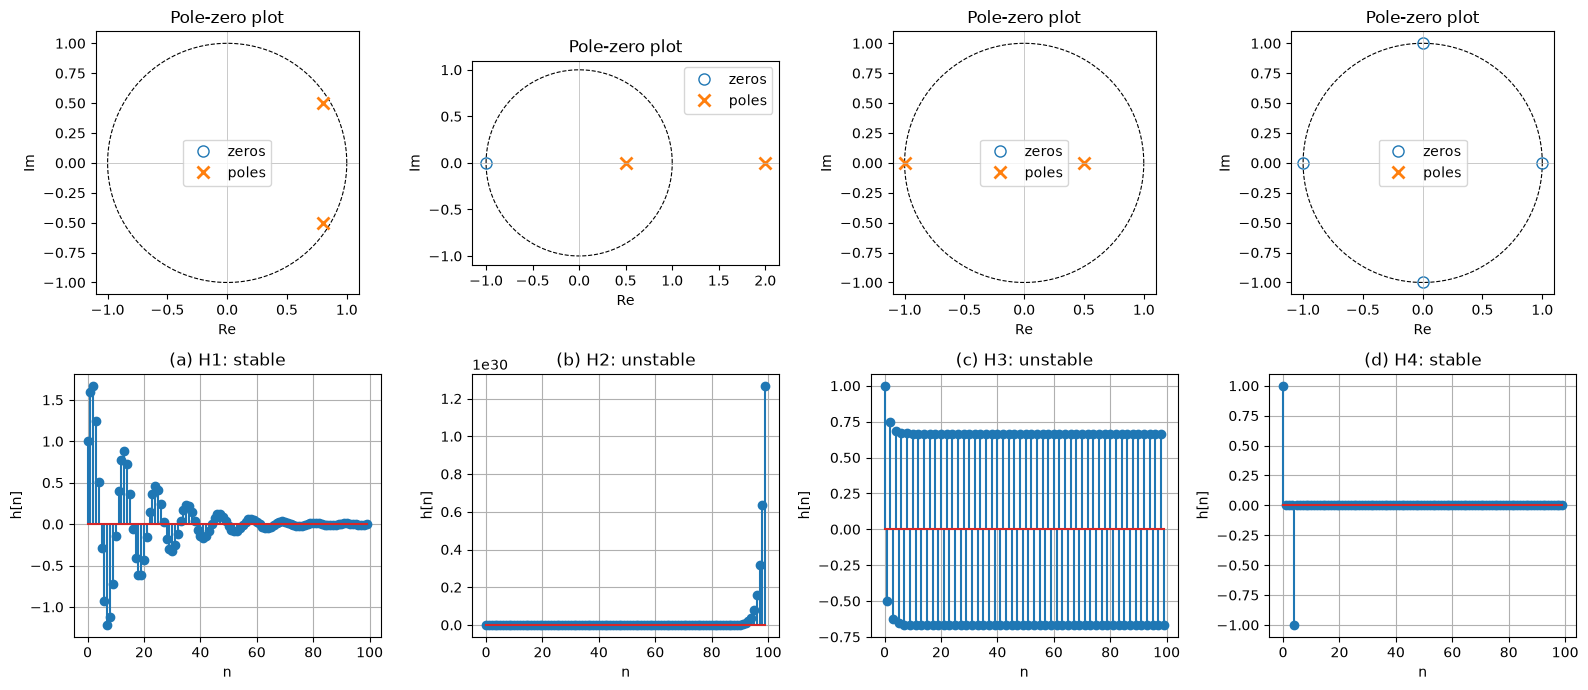

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

systems = {
    "(a) H1": ([1], [1, -1.6, 0.89]),
    "(b) H2": ([1, 1], [1, -2.5, 1]),
    "(c) H3": ([1], [1, 0.5, -0.5]),
    "(d) H4": ([1, 0, 0, 0, -1], [1]),
}

def zplane(b, a, ax=None):
    z, p, _ = signal.tf2zpk(b, a)
    if ax is None:
        ax = plt.gca()

    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=8, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=8, mew=2, label="poles")
    ax.axhline(0, color="0.7", lw=0.5)
    ax.axvline(0, color="0.7", lw=0.5)
    ax.set_aspect("equal")
    ax.set_title("Pole-zero plot")
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.legend()
    return z, p

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for col, (name, (b, a)) in enumerate(systems.items()):
    z, p = zplane(b, a, axes[0, col])

    impulse = np.zeros(100)
    impulse[0] = 1
    h = signal.lfilter(b, a, impulse)

    stable = np.all(np.abs(p) < 1)
    axes[1, col].stem(np.arange(len(h)), h)
    axes[1, col].set_title(f"{name}: {'stable' if stable else 'unstable'}")
    axes[1, col].set_xlabel("n")
    axes[1, col].set_ylabel("h[n]")
    axes[1, col].grid(True)

    print(
        f"{name}: poles={p}, pole magnitudes={np.abs(p)}, "
        f"{'stable' if stable else 'unstable'}, "
        f"max |h[n]| over 100 samples={np.max(np.abs(h)):.3g}"
    )

plt.tight_layout()
plt.show()

(a) (H1): stable. The complex-conjugate poles have magnitude. so the impulse response decays, though slowly.

(b) (H2): unstable. its poles are approximately 2 and 0.5. the pole outside the unit circle makes the impulse response grow.

(c) (H3): unstable. its poles are 0.5 and -1. the poles at -1 produces a nondecaying alternating component, so it is not stable.

(d) (H4): stable. It has no poles. so it is a finite-duration response.

**TASK 4.5 – DESIGN A RESONATOR**

Sampling Frequency: 8000 Hz
Resonance Frequency: 1000 Hz
Pole Radius: 0.97

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]


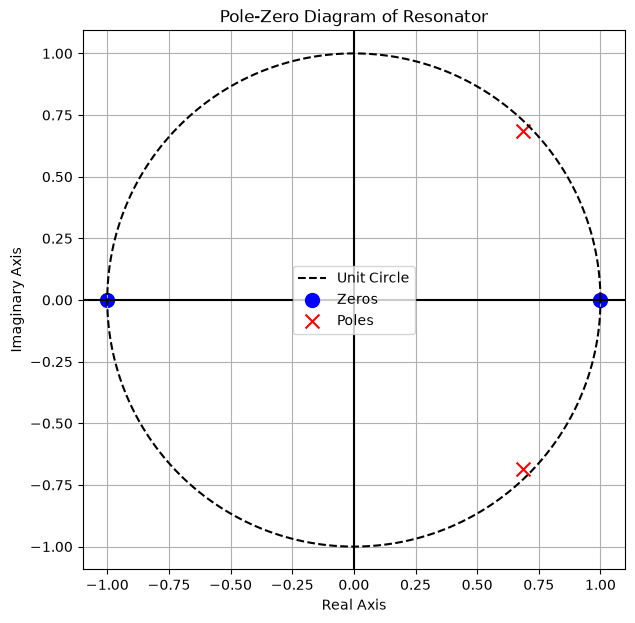

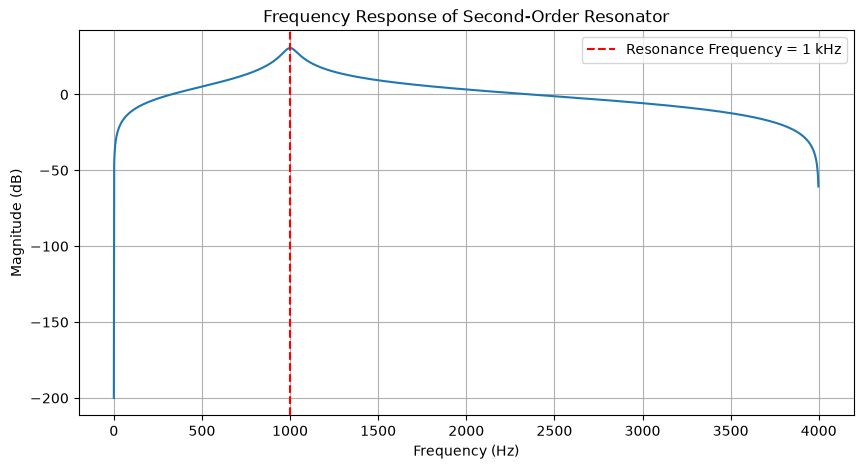


Resonator applied successfully.


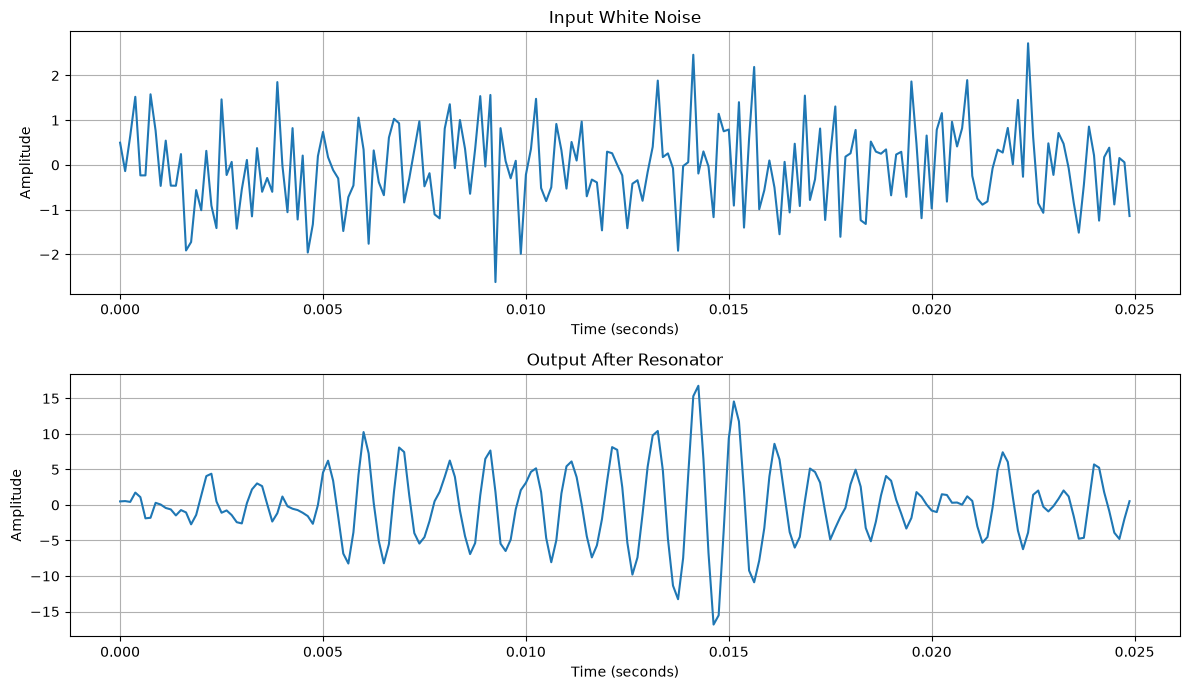

Playing resonator output...



Stability Check:
The resonator is STABLE.

Task 4.5 completed successfully.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, lfilter
from IPython.display import Audio, display

fs = 8000
f0 = 1000 
r = 0.97

w0 = 2 * np.pi * f0 / fs

print("Sampling Frequency:", fs, "Hz")
print("Resonance Frequency:", f0, "Hz")
print("Pole Radius:", r)

b = [1, 0, -1]

a = [1, -2*r*np.cos(w0), r**2]

print("\nNumerator coefficients:", b)
print("Denominator coefficients:", a)

zeros = np.roots(b)
poles = np.roots(a)

print("\nZeros:", zeros)
print("Poles:", poles)

theta = np.linspace(0, 2*np.pi, 500)

plt.figure(figsize=(7, 7))

plt.plot(np.cos(theta), np.sin(theta),
         'k--', label='Unit Circle')

plt.scatter(np.real(zeros), np.imag(zeros),
            color='blue', marker='o', s=100,
            label='Zeros')

plt.scatter(np.real(poles), np.imag(poles),
            color='red', marker='x', s=100,
            label='Poles')

plt.axhline(0, color='black')
plt.axvline(0, color='black')

plt.xlabel('Real Axis')
plt.ylabel('Imaginary Axis')
plt.title('Pole-Zero Diagram of Resonator')

plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()

w, h = freqz(b, a, worN=2048, fs=fs)

magnitude = 20 * np.log10(np.maximum(np.abs(h), 1e-10))

plt.figure(figsize=(10, 5))

plt.plot(w, magnitude)

plt.axvline(f0, color='red', linestyle='--',
            label='Resonance Frequency = 1 kHz')

plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('Frequency Response of Second-Order Resonator')

plt.legend()
plt.grid(True)
plt.show()

np.random.seed(42)

duration = 3
x = np.random.randn(duration * fs)

y = lfilter(b, a, x)

print("\nResonator applied successfully.")

t = np.arange(len(x)) / fs

plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t[:200], x[:200])
plt.title('Input White Noise')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t[:200], y[:200])
plt.title('Output After Resonator')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True)

plt.tight_layout()
plt.show()

# 10. Listen to the Output
print("Playing resonator output...")
display(Audio(y, rate=fs))

# 11. Check Stability
print("\nStability Check:")

if np.all(np.abs(poles) < 1):
    print("The resonator is STABLE.")
else:
    print("The resonator is UNSTABLE.")

print("\nTask 4.5 completed successfully.")

## Analysis questions

**1. Explain the effect of r on the bandwidth of the resonance in Task 4.3.**

The 3 dB bandwidth is approximately 2(1 − r) rad/sample, so as r → 1 the peak at ω = π/4 becomes narrower and sharper, and h(n) decays more slowly (longer ringing). A smaller r gives a wide, low peak and a fast-decaying h(n).

**2. What happens to h(n) when a pole lies exactly on the unit circle?**

h(n) neither decays nor grows. For a pole pair at r = 1 it is a sustained sinusoid of constant amplitude, so the system is marginally stable. Σ|h(n)| is infinite, so it is not BIBO stable, and a bounded input at the resonant frequency produces an unbounded output.

**3. Why does placing zeros at z = ±1 make the resonator a band-pass filter?**

A zero at z = 1 gives H = 0 at ω = 0 (DC), and a zero at z = −1 gives H = 0 at ω = π (fs/2). The pole pair gives a peak at 1 kHz between them. The response is therefore blocked at both ends and passes a band around 1 kHz.

**4. Use the stability triangle to check Task 4.4 (a)–(c).**

For A(z) = 1 + a₁z⁻¹ + a₂z⁻², the system is stable if |a₂| < 1, 1 + a₁ + a₂ > 0 and 1 − a₁ + a₂ > 0.

- (a) a₁ = −1.6, a₂ = 0.89: |a₂| = 0.89 < 1, 1 + a₁ + a₂ = 0.29 > 0, 1 − a₁ + a₂ = 3.49 > 0. **Stable** (pole radius √0.89 = 0.943).
- (b) a₁ = −2.5, a₂ = 1: |a₂| = 1, which is not < 1. **Unstable** (poles at 2 and 0.5; h(n) grows).
- (c) a₁ = 0.5, a₂ = −0.5: 1 − a₁ + a₂ = 0, which is on the triangle boundary. **Marginally stable**: poles at 0.5 and −1, so h(n) = (1/3)(0.5)ⁿ + (2/3)(−1)ⁿ does not decay.

## Git repository
https://github.com/PRIME-O/COU07506-labs

## AI-use statement
AI tools used: Claude (Anthropic chat assistant)

Used for: explaining the Task 4.1 to 4.5 code

How I verified the output: checked residuez results against my hand partial fractions and against lfilter, confirmed h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ, and compared stability classifications from the poles with the growth of h(n).
